# Análisis de FID y entropía de Shannon

Este notebook contiene los procedimientos utilizados para comparar las imágenes de la clase positiva de los conjuntos de entrenamiento balanceado (1:1) y desbalanceado (3:1) del conjunto BCS-DBT.

Se realizaron los siguientes análisis:

- **Distancia de Fréchet Inception (FID):** comparación de las distribuciones de características extraídas mediante una capa intermedia de InceptionV3.
- **Entropía de Shannon:** cálculo de la entropía de las imágenes y comparación de sus valores medios y desviaciones estándar.
- **Verificaciones adicionales:** comprobación de las cantidades de imágenes por clase y cálculo de una FID de control.

Los análisis requieren los archivos `X_train_3a1.npy`, `X_train_1a1.npy`, `y_train_3a1.npy` y `y_train_1a1.npy`, almacenados en Google Drive. Las rutas deben adaptarse al entorno de ejecución.

El notebook conserva los resultados de las ejecuciones originales y no constituye un procedimiento autónomo de descarga y generación de los conjuntos de datos.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import gc
import pandas as pd
from matplotlib import pyplot as plt
from scipy.linalg import sqrtm
import tensorflow as tf
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input
from tensorflow.keras.models import Model

In [ ]:
import numpy as np
import h5py
import os

# Configura tus rutas reales de Drive aquí
ruta_drive = '/content/drive/MyDrive/Colab Notebooks/Imagenes3a1/'
archivo_orig_npy = os.path.join(ruta_drive, 'X_train_3a1.npy')
archivo_aug_npy = os.path.join(ruta_drive, 'X_train_1a1.npy')

# Nuevos archivos HDF5 que se crearán en tu Drive
archivo_orig_h5 = os.path.join(ruta_drive, 'X_train_3a1.h5')
archivo_aug_h5 = os.path.join(ruta_drive, 'X_train_1a1.h5')

def npy_to_h5_low_ram(npy_path, h5_path, chunk_size=32):
    """ Convierte un .npy gigante de Drive a .h5 en porciones para proteger la RAM """
    if os.path.exists(h5_path):
        print(f"El archivo {h5_path} ya existe. Saltando conversión.")
        return

    # Mapeamos el npy (esperando que permita la lectura por trozos)
    data_npy = np.load(npy_path, mmap_mode='r')
    shape = data_npy.shape
    dtype = data_npy.dtype

    print(f"Convirtiendo {os.path.basename(npy_path)} ({shape}) a HDF5...")

    with h5py.File(h5_path, 'w') as f:
        # Creamos el dataset vacío en el archivo H5
        dset = f.create_dataset('images', shape=shape, dtype=dtype, chunks=(chunk_size, *shape[1:]))

        # Copiamos trozo por trozo
        for i in range(0, shape[0], chunk_size):
            dset[i:i+chunk_size] = data_npy[i:i+chunk_size]

    print(f"¡Convertido con éxito!: {h5_path}")

# Ejecutamos la conversión para ambos datasets
npy_to_h5_low_ram(archivo_orig_npy, archivo_orig_h5)
npy_to_h5_low_ram(archivo_aug_npy, archivo_aug_h5)

Convirtiendo X_train_3a1.npy ((2904, 512, 512, 1)) a HDF5...
¡Convertido con éxito!: /content/drive/MyDrive/Colab Notebooks/Imagenes3a1/X_train_3a1.h5
Convirtiendo X_train_1a1.npy ((3197, 512, 512, 1)) a HDF5...
¡Convertido con éxito!: /content/drive/MyDrive/Colab Notebooks/Imagenes3a1/X_train_1a1.h5


## Corte

In [ ]:
import tensorflow as tf
# --- CONFIGURACIÓN DE GPU ---
# Esto evita que TensorFlow se adueñe de toda la memoria de la GPU y falle por "Out of Memory"
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"--> ¡GPU Detectada y Optimizada!: {gpus}")
    except RuntimeError as e:
        print(e)
else:
    print("--> No se detectó GPU. Se usará la CPU (será más lento).")

--> ¡GPU Detectada y Optimizada!: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Modifica estas rutas con el nombre real de tu carpeta en Drive
!cp "/content/drive/MyDrive/Colab Notebooks/Imagenes3a1/X_train_3a1.npy" "/content/X_train_3a1.npy"
!cp "/content/drive/MyDrive/Colab Notebooks/Imagenes3a1/X_train_1a1.npy" "/content/X_train_1a1.npy"

print("¡Archivos copiados con éxito al disco local de la máquina virtual!")

¡Archivos copiados con éxito al disco local de la máquina virtual!


In [ ]:
import numpy as np
import h5py
import os

archivo_orig_npy = '/content/X_train_3a1.npy'
archivo_aug_npy = '/content/X_train_1a1.npy'

archivo_orig_h5 = '/content/dataset_orig.h5'
archivo_aug_h5 = '/content/dataset_aug.h5'

def npy_to_h5_float_fixed(npy_path, h5_path, chunk_size=16):
    # mmap_mode='r' funciona perfecto en el disco local
    data_npy = np.load(npy_path, mmap_mode='r')
    shape = data_npy.shape

    # FORZAMOS el tipo de datos a float32 para no perder los decimales entre 0 y 1
    dtype = np.float32

    print(f"Re-convirtiendo {os.path.basename(npy_path)} preservando decimales...")

    # Eliminamos versiones viejas del h5 si existen
    if os.path.exists(h5_path):
        os.remove(h5_path)

    with h5py.File(h5_path, 'w') as f:
        dset = f.create_dataset('images', shape=shape, dtype=dtype, chunks=(chunk_size, *shape[1:]))

        for i in range(0, shape[0], chunk_size):
            # Guardamos los datos asegurando que mantengan sus valores float originales
            dset[i:i+chunk_size] = data_npy[i:i+chunk_size].astype(np.float32)

    print(f"¡Creado con éxito (Formato Float32)!: {h5_path}")

# Ejecutamos la conversión correcta
npy_to_h5_float_fixed(archivo_orig_npy, archivo_orig_h5)
npy_to_h5_float_fixed(archivo_aug_npy, archivo_aug_h5)

# Opcional: Borramos los .npy locales para liberar espacio en el disco duro
!rm /content/X_train_3a1.npy
!rm /content/X_train_1a1.npy

Re-convirtiendo X_train_3a1.npy preservando decimales...
¡Creado con éxito (Formato Float32)!: /content/dataset_orig.h5
Re-convirtiendo X_train_1a1.npy preservando decimales...
¡Creado con éxito (Formato Float32)!: /content/dataset_aug.h5


In [ ]:
import numpy as np

ruta = '/content/drive/MyDrive/Colab Notebooks/Imagenes3a1/'

y_train_3a1 = np.load(ruta + 'y_train_3a1.npy')
y_train_1a1 = np.load(ruta + 'y_train_1a1.npy')
# Buscamos los índices (posiciones) donde la clase es la minoritaria (ej: clase 1)
indices_minoritarios_orig = np.where(y_train_3a1 == 1)[0]
indices_minoritarios_aug = np.where(y_train_1a1 == 1)[0]

print(f"Imágenes de la clase minoritaria original: {len(indices_minoritarios_orig)}")
print(f"Imágenes de la clase minoritaria aumentada: {len(indices_minoritarios_aug)}")

Imágenes de la clase minoritaria original: 726
Imágenes de la clase minoritaria aumentada: 1597


In [ ]:
import gc
import h5py
import numpy as np
from scipy.linalg import sqrtm
import tensorflow as tf
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras import backend as K
from tensorflow.keras.applications.inception_v3 import InceptionV3
from tensorflow.keras.models import Model

# =====================================================================
# VERIFICACIÓN Y CONFIGURACIÓN DE LA GPU
# =====================================================================
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"--> ¡GPU Detectada y Optimizada con éxito!: {gpus}")
    except RuntimeError as e:
        print(e)
else:
    print("⚠️ ALERTA: No se detectó GPU. Se usará la CPU (será lento y puede dar error de RAM).")

# =====================================================================
# AQUÍ SE DEFINE EXPLICITAMENTE LA CAPA MIXED6 DE INCEPTIONV3
# =====================================================================
def get_feature_extractor():
    """
    Carga InceptionV3, busca la capa 'mixed6' y le añade una capa de
    Global Average Pooling para colapsar las dimensiones espaciales,
    evitando el error OOM (Out of Memory) de la GPU.
    """
    base_model = InceptionV3(include_top=False, weights='imagenet', pooling=None)

    # 1. Buscamos la capa mixed6
    target_layer = None
    for layer in base_model.layers:
        if 'mixed6' in layer.name or 'mixed_6' in layer.name:
            target_layer = layer.name
            break

    if target_layer is None:
        for layer in reversed(base_model.layers):
            if 'mixed' in layer.name:
                target_layer = layer.name
                break

    print(f"--> [OK] Conectando con capa intermedia: {target_layer}")

    # 2. Tomamos la salida de mixed6 (que es de forma 30x30x768)
    mixed6_output = base_model.get_layer(target_layer).output

    # 3. TRUCO ANTI-OOM: Promediamos los píxeles espaciales (30x30) para transformarlos en un vector plano de 768
    # Esto reduce el peso de los datos acumulados en la GPU por un factor de 900x.
    pooled_output = GlobalAveragePooling2D()(mixed6_output)

    # Creamos el nuevo modelo extractor optimizado
    return Model(inputs=base_model.input, outputs=pooled_output)

# =====================================================================
# GENERADOR INDEXADO (Lee solo los índices que le pide y_train)
# =====================================================================
def h5_generator_por_indices(h5_path, lista_indices):
    with h5py.File(h5_path, 'r') as f:
        dataset = f['images']
        for idx in lista_indices:
            img = dataset[int(idx)]
            if img.ndim == 3 and img.shape[-1] == 1:
                img = img[:, :, 0]
            yield img

def extract_features_por_clase(h5_path, lista_indices, model, batch_size=16):
    n_samples = len(lista_indices)

    with h5py.File(h5_path, 'r') as f:
        height = f['images'].shape[1]
        width = f['images'].shape[2]

    # CAMBIO CRÍTICO: Aquí ahora le decimos a TF que lea float32
    dataset = tf.data.Dataset.from_generator(
        lambda: h5_generator_por_indices(h5_path, lista_indices),
        output_signature=tf.TensorSpec(shape=(height, width), dtype=tf.float32)
    )

    # Preprocesamiento optimizado para InceptionV3 [0, 1] -> [-1, 1]
    def process_tf(img):
        # Creamos los 3 canales RGB exigidos por Inception
        img_rgb = tf.stack([img, img, img], axis=-1)

        # Como los datos ya son float32 y están entre 0 y 1,
        # aplicamos la fórmula directa para llevarlos a [-1, 1]
        img_rgb = (img_rgb * 2.0) - 1.0
        return img_rgb

    dataset = dataset.map(process_tf, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    # Predicción en GPU
    features = model.predict(dataset, steps=int(np.ceil(n_samples / batch_size)), verbose=1)

    K.clear_session()
    gc.collect()
    return features

# =====================================================================
# FUNCIÓN PRINCIPAL DEL FID FILTRADO
# =====================================================================
def calculate_fid_clase_aislada(path_orig_h5, idx_orig, path_aug_h5, idx_aug, batch_size=16):
    # Inicializamos el extractor (InceptionV3 cortado en mixed6 + Pooling)
    model = get_feature_extractor()

    print("\nPaso 1/3: Procesando EXCLUSIVAMENTE la clase minoritaria original...")
    f_orig = extract_features_por_clase(path_orig_h5, idx_orig, model, batch_size)

    print("\nPaso 2/3: Procesando EXCLUSIVAMENTE la clase minoritaria aumentada...")
    f_aug = extract_features_por_clase(path_aug_h5, idx_aug, model, batch_size)

    print("\nPaso 3/3: Calculando estadísticas e interpolando covarianza...")
    mu_orig, sigma_orig = f_orig.mean(axis=0), np.cov(f_orig, rowvar=False)
    mu_aug, sigma_aug = f_aug.mean(axis=0), np.cov(f_aug, rowvar=False)

    # Regularización para evitar la advertencia de matriz singular (LinAlgWarning)
    eps = 1e-6
    offset = np.eye(sigma_orig.shape[0]) * eps
    sigma_orig_reg = sigma_orig + offset
    sigma_aug_reg = sigma_aug + offset

    ssdiff = np.sum((mu_orig - mu_aug) ** 2.0)
    covmean = sqrtm(sigma_orig_reg.dot(sigma_aug_reg))
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid_score = ssdiff + np.trace(sigma_orig_reg + sigma_aug_reg - 2.0 * covmean)

    del f_orig, f_aug
    gc.collect()
    return fid_score

# =====================================================================
# 5. EJECUCIÓN (Apunta a tus archivos H5 locales en la PC virtual)
# =====================================================================
h5_local_original = '/content/dataset_orig.h5'
h5_local_aumentado = '/content/dataset_aug.h5'

# Ejecutamos el cálculo enfocado únicamente en la clase que sufrió el aumento
score_fid_real = calculate_fid_clase_aislada(
    h5_local_original, indices_minoritarios_orig,
    h5_local_aumentado, indices_minoritarios_aug,
    batch_size=16
)

print(f"\n" + "="*50)
print(f" FID SCORE REAL DE LA CLASE MINORITARIA: {score_fid_real:.4f}")
print("="*50)

--> ¡GPU Detectada y Optimizada con éxito!: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
--> [OK] Conectando con capa intermedia: mixed6

Paso 1/3: Procesando EXCLUSIVAMENTE la clase minoritaria original...
46/46 ━━━━━━━━━━━━━━━━━━━━ 16s 250ms/step

Paso 2/3: Procesando EXCLUSIVAMENTE la clase minoritaria aumentada...
100/100 ━━━━━━━━━━━━━━━━━━━━ 19s 183ms/step

Paso 3/3: Calculando estadísticas e interpolando covarianza...

 FID SCORE REAL DE LA CLASE MINORITARIA: 0.0226


In [ ]:
import h5py
import numpy as np

with h5py.File('/content/dataset_orig.h5', 'r') as f_orig, h5py.File('/content/dataset_aug.h5', 'r') as f_aug:
    img_o = f_orig['images'][int(indices_minoritarios_orig[0])]
    img_a = f_aug['images'][int(indices_minoritarios_aug[0])]

    # Comparamos si la primera imagen de la clase minoritaria es idéntica en ambos archivos
    son_idénticos = np.array_equal(img_o, img_a)
    print(f"¿La primera imagen mapeada es exactamente el mismo clon numérico?: {son_idénticos}")
    print(f"Suma de píxeles original: {np.sum(img_o)} | Suma aumentado: {np.sum(img_a)}")

¿La primera imagen mapeada es exactamente el mismo clon numérico?: True
Suma de píxeles original: 33622.8671875 | Suma aumentado: 33622.8671875


In [ ]:
# Verificamos si los índices que le pasamos al extractor son exactamente los mismos
if np.array_equal(indices_minoritarios_orig, indices_minoritarios_aug):
    print("⚠️ ¡ALERTA! Le estás pasando exactamente la misma lista de posiciones a ambos datasets.")
    print("Por lo tanto, el extractor lee las mismas imágenes y el FID da cero.")
else:
    print("Las listas de índices son diferentes. El problema es más profundo.")

Las listas de índices son diferentes. El problema es más profundo.


In [ ]:
# Tomamos los índices de la clase 0 (mayoritaria) y clase 1 (minoritaria) del dataset original
idx_clase_0 = np.where(y_train_3a1 == 0)[0][:200] # Solo 200 imágenes para ir rápido
idx_clase_1 = np.where(y_train_3a1 == 1)[0][:200]

print("Corriendo prueba de control: Clase 0 vs Clase 1 (Mismo archivo)...")
score_control = calculate_fid_clase_aislada(
    '/content/dataset_orig.h5', idx_clase_0,
    '/content/dataset_orig.h5', idx_clase_1,
    batch_size=16
)

print(f"\n[CONTROL] FID entre Clase 0 y Clase 1: {score_control:.4f}")

Corriendo prueba de control: Clase 0 vs Clase 1 (Mismo archivo)...
--> [OK] Conectando con capa intermedia: mixed6

Paso 1/3: Procesando EXCLUSIVAMENTE la clase minoritaria original...
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 600ms/step

Paso 2/3: Procesando EXCLUSIVAMENTE la clase minoritaria aumentada...
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step

Paso 3/3: Calculando estadísticas e interpolando covarianza...

[CONTROL] FID entre Clase 0 y Clase 1: 0.1677


In [ ]:
import gc
import h5py
import numpy as np
from skimage.measure import shannon_entropy

def calcular_entropia_h5_por_clase(h5_path, lista_indices, descripcion="Dataset"):
    """
    Calcula la entropía de Shannon promedio para un grupo específico de imágenes
    leyendo directamente del archivo H5 de forma secuencial (Anti-RAM).
    """
    entropias = []
    total = len(lista_indices)

    print(f"📊 Calculando entropía para {descripcion} ({total} imágenes)...")

    with h5py.File(h5_path, 'r') as f:
        dataset = f['images']

        for contador, idx in enumerate(lista_indices):
            img = dataset[int(idx)]

            # Si tiene un canal extra flotante, lo aplanamos a 2D
            if img.ndim == 3 and img.shape[-1] == 1:
                img = img[:, :, 0]

            # Calculamos la entropía de Shannon (base 2) para el corte actual
            val_entropia = shannon_entropy(img)
            entropias.append(val_entropia)

            # Imprimir progreso cada 500 imágenes
            if (contador + 1) % 500 == 0 or (contador + 1) == total:
                print(f"   Procesadas: {contador + 1}/{total}")

    gc.collect()
    return np.array(entropias)

# =====================================================================
# EJECUCIÓN DEL CÁLCULO
# =====================================================================
h5_local_original = '/content/dataset_orig.h5'
h5_local_aumentado = '/content/dataset_aug.h5'

# Usamos las mismas listas de índices que obtuviste con tu y_train
ent_originales = calcular_entropia_h5_por_clase(h5_local_original, indices_minoritarios_orig, "Clase Minoritaria Real")
ent_aumentados = calcular_entropia_h5_por_clase(h5_local_aumentado, indices_minoritarios_aug, "Clase Minoritaria Aumentada")

# Estadísticas finales
mean_orig, std_orig = np.mean(ent_originales), np.std(ent_originales)
mean_aug, std_aug = np.mean(ent_aumentados), np.std(ent_aumentados)

print("\n" + "="*60)
print(" 📈 RESULTADOS DE ENTROPÍA (SHANNON - bits/píxel)")
print("="*60)
print(f"Cortes Centrales Reales   -> Media: {mean_orig:.4f} | Desviación Est.: {std_orig:.4f}")
print(f"Cortes Contiguos Aumentados -> Media: {mean_aug:.4f} | Desviación Est.: {std_aug:.4f}")
print("="*60)

📊 Calculando entropía para Clase Minoritaria Real (726 imágenes)...
   Procesadas: 500/726
   Procesadas: 726/726
📊 Calculando entropía para Clase Minoritaria Aumentada (1597 imágenes)...
   Procesadas: 500/1597
   Procesadas: 1000/1597
   Procesadas: 1500/1597
   Procesadas: 1597/1597

 📈 RESULTADOS DE ENTROPÍA (SHANNON - bits/píxel)
Cortes Centrales Reales   -> Media: 7.2371 | Desviación Est.: 2.5746
Cortes Contiguos Aumentados -> Media: 7.1898 | Desviación Est.: 2.6043


## Corte

In [ ]:
import numpy as np
ruta = '/content/drive/MyDrive/Colab Notebooks/Imagenes3a1/'
X_train_3a1 = np.load(ruta + 'X_train_3a1.npy')
X_train_1a1 = np.load(ruta + 'X_train_1a1.npy')
y_train_3a1 = np.load(ruta + 'y_train_3a1.npy')
y_train_1a1 = np.load(ruta + 'y_train_1a1.npy')

In [ ]:
valores_unicos, conteos = np.unique(y_train_3a1, return_counts=True)
print("y_train_3a1: ", valores_unicos, conteos)
valores_unicos, conteos = np.unique(y_train_1a1, return_counts=True)
print("y_train_1a1: ", valores_unicos, conteos)

y_train_3a1:  [0 1] [2178  726]
y_train_1a1:  [0 1] [1600 1597]


In [ ]:
X_train_1a1.shape

(3197, 512, 512, 1)

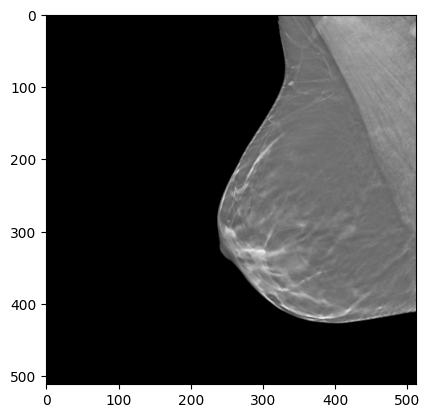

In [ ]:
plt.imshow(X_train_1a1[5,:, :, 0],cmap='grey')